# Лабораторная работа №8: Active learning и human-in-the-loop

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать random, entropy и diversity sampling.
- Провести несколько AL-итераций.
- Построить learning curves при равном бюджете.


## Теоретическая часть

Active learning выбирает следующий batch из pool. Uncertainty ищет неуверенные объекты, diversity покрывает пространство, disagreement использует расхождение моделей. Сравнение корректно только при одинаковом annotation budget.


### Математическая постановка

Entropy sampling: $u(x)=-\sum_c p(c\mid x)\log p(c\mid x)$. Diversity можно реализовать k-center: выбрать объект, максимизирующий расстояние до уже размеченного множества.


### Материалы

- [Active Learning survey](https://arxiv.org/abs/2009.00236)
- [scikit-learn calibration](https://scikit-learn.org/stable/modules/calibration.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Работа выполняется на изображениях рукописных цифр `sklearn.datasets.load_digits`; oracle в этом воспроизводимом эксперименте симулирует человека, открывая истинную метку только после отбора объекта. FAST_DEV_RUN — два раунда проверки кода, полный режим — восемь раундов и повторный random baseline.

In [13]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Стратифицированный отложенный тест

*Вес: 1 балл.*

**Постановка.** Этап «стратифицированный отложенный тест» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Разделите изображения цифр по стратифицированному правилу до выбора стратегии.
2. Сохраните и предъявите индексы train/test изображений цифр.

**Результат.** индексы train/test изображений цифр.

**Критерий принятия.** Задание считается принятым, если индексы train/test изображений цифр получены из фактических входов этого этапа и доступны для проверки.

In [14]:
# --- cv08-09: стратифицированный отложенный тест ---
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

# Тест фиксируется ДО выбора AL-стратегии: все стратегии сравниваются на одних и тех же данных.
digits = load_digits()
X_all = digits.images.astype(np.float32) / 16.0     # (N, 8, 8), пиксели в [0, 1]
y_all = digits.target.astype(np.int64)
N = len(X_all)

train_idx, test_idx = train_test_split(
    np.arange(N), test_size=0.25, stratify=y_all, random_state=SEED)
train_idx = np.sort(train_idx)
test_idx = np.sort(test_idx)

print(f"Всего: {N} | train: {len(train_idx)} | test: {len(test_idx)}")
print("train по классам:", np.bincount(y_all[train_idx], minlength=10))
print("test  по классам:", np.bincount(y_all[test_idx], minlength=10))

save_json("split_indices.json", {
    "seed": SEED, "stratified": True, "n_total": int(N),
    "train_indices": train_idx.tolist(), "test_indices": test_idx.tolist(),
})
print("→ artifacts/split_indices.json")

Всего: 1797 | train: 1347 | test: 450
train по классам: [133 136 133 137 136 136 136 134 131 135]
test  по классам: [45 46 44 46 45 46 45 45 43 45]
→ artifacts/split_indices.json


### Начальная размеченная выборка

*Вес: 1 балл.*

**Постановка.** Этап «начальная размеченная выборка» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Задайте initial с каждым классом и неразмеченный pool только из train.
2. Сохраните и предъявите непересекающиеся initial и pool.

**Результат.** непересекающиеся initial и pool.

**Критерий принятия.** Задание считается принятым, если непересекающиеся initial и pool получены из фактических входов этого этапа и доступны для проверки.

In [15]:
# --- cv08-11: initial (по 2 объекта на класс) и непересекающийся pool ---
CLASSES = list(range(10))
INIT_PER_CLASS = 2

rng_init = np.random.default_rng(SEED)
initial_idx = []
for c in CLASSES:
    cls_train = train_idx[y_all[train_idx] == c]
    initial_idx.extend(rng_init.choice(cls_train, size=INIT_PER_CLASS, replace=False).tolist())
initial_idx = np.array(sorted(initial_idx), dtype=int)

pool_idx = np.array(sorted(set(train_idx.tolist()) - set(initial_idx.tolist())), dtype=int)

# Проверки пересечений — именно они являются наблюдаемым результатом этапа.
assert set(initial_idx) & set(pool_idx) == set(), "initial и pool пересекаются!"
assert len(initial_idx) + len(pool_idx) == len(train_idx), "train разбит не полностью"
assert len(set(test_idx) & (set(initial_idx) | set(pool_idx))) == 0, "test попал в обучение!"

print(f"initial: {len(initial_idx)} объектов ({INIT_PER_CLASS} на класс)")
print(f"pool:    {len(pool_idx)} объектов")
print("initial по классам:", np.bincount(y_all[initial_idx], minlength=10))
print("pool    по классам:", np.bincount(y_all[pool_idx], minlength=10))
print("|initial ∩ pool| =", len(set(initial_idx) & set(pool_idx)))

initial: 20 объектов (2 на класс)
pool:    1327 объектов
initial по классам: [2 2 2 2 2 2 2 2 2 2]
pool    по классам: [131 134 131 135 134 134 134 132 129 133]
|initial ∩ pool| = 0


### Протокол симулированного разметчика

*Вес: 1 балл.*

**Постановка.** Этап «протокол симулированного разметчика» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните split и документируйте, что oracle открывает метку лишь после выбора.
2. Сохраните и предъявите artifacts/split.json с происхождением меток.

**Результат.** artifacts/split.json с происхождением меток.

**Критерий принятия.** Задание считается принятым, если artifacts/split.json с происхождением меток получены из фактических входов этого этапа и доступны для проверки.

In [16]:
# --- cv08-13: oracle открывает метку ТОЛЬКО после отбора объекта ---
class Oracle:
    """Симулированный разметчик. Стратегии видят только X из pool,
    истинные метки доступны исключительно через query() после выбора."""
    def __init__(self, X, y):
        self._y = y
        self.n_queries = 0
        self.query_log = []          # провенанс меток: когда/кем/что запрошено

    def query(self, indices, iteration, strategy):
        indices = np.asarray(indices, dtype=int)
        labels = self._y[indices].copy()
        self.n_queries += len(indices)
        for i, lab in zip(indices, labels):
            self.query_log.append({"iteration": int(iteration), "strategy": strategy,
                                   "index": int(i), "label": int(lab)})
        return labels

split_payload = {
    "dataset": "sklearn.datasets.load_digits",
    "n_total": int(N),
    "train_indices": train_idx.tolist(),
    "test_indices": test_idx.tolist(),
    "initial_indices": initial_idx.tolist(),
    "pool_indices": pool_idx.tolist(),
    "label_provenance": {
        "protocol": "simulated_oracle_after_selection",
        "description": ("Стратегии работают только с X из pool. Истинные y[pool] открываются "
                        "Oracle.query() ПОСЛЕ отбора batch; лог запросов — query_log."),
        "initial_labels_source": "oracle (считаются размеченными человеком заранее)",
        "test_labels_usage": "только финальная оценка, никогда — для выбора объектов",
    },
    "seed": SEED,
}
save_json("split.json", split_payload)

print("artifacts/split.json сохранён. Ключи:", list(split_payload.keys()))
print("Пример происхождения initial-меток:", [(int(i), int(y_all[i])) for i in initial_idx[:5]])

artifacts/split.json сохранён. Ключи: ['dataset', 'n_total', 'train_indices', 'test_indices', 'initial_indices', 'pool_indices', 'label_provenance', 'seed']
Пример происхождения initial-меток: [(150, 0), (153, 3), (180, 2), (364, 7), (673, 7)]


### Три стратегии запроса

*Вес: 1 балл.*

**Постановка.** Этап «три стратегии запроса» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте случайный, энтропийный и k-center выбор; в k-center обновляйте расстояния после каждого объекта.
2. Сохраните и предъявите выбор random, entropy и k-center.

**Результат.** выбор random, entropy и k-center.

**Критерий принятия.** Задание считается принятым, если выбор random, entropy и k-center получены из фактических входов этого этапа и доступны для проверки.

In [17]:
# --- cv08-15: признаки, классификатор и три стратегии отбора ---
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

FEATURES = X_all.reshape(N, -1).astype(np.float32)   # 64 признака (8x8 пикселей)
# Масштабирование на train БЕЗ меток: это не утечка и делает признаки сравнимыми для k-center.
SCALER = StandardScaler().fit(FEATURES[train_idx])
FEAT_SCALED = SCALER.transform(FEATURES).astype(np.float32)

def make_classifier():
    return LogisticRegression(max_iter=2000, C=1.0, random_state=SEED)

def fit_model(labeled_idx):
    return make_classifier().fit(FEAT_SCALED[labeled_idx], y_all[labeled_idx])

def predict_proba(clf, idx):
    return clf.predict_proba(FEAT_SCALED[idx])

def select_random(pool_idx, n, rng):
    """Random sampling: контрольный baseline."""
    n = int(min(n, len(pool_idx)))
    return [int(i) for i in rng.choice(pool_idx, size=n, replace=False)]

def select_entropy(proba, pool_idx, n):
    """Entropy sampling: u(x) = -sum_c p log p; берём самые неуверенные объекты."""
    eps = 1e-12
    ent = -(proba * np.log(proba + eps)).sum(axis=1)
    order = np.argsort(-ent)[:int(n)]
    return [int(pool_idx[j]) for j in order]

def select_kcenter(pool_idx, labeled_idx, n):
    """k-center: жадно берём объект с максимальным расстоянием до размеченного множества;
    расстояния обновляются после КАЖДОГО выбранного объекта (а не один раз на batch)."""
    pool_idx = np.asarray(pool_idx, dtype=int)
    labeled_idx = np.asarray(labeled_idx, dtype=int)
    feats_pool = FEAT_SCALED[pool_idx]
    min_dist = ((feats_pool[:, None, :] - FEAT_SCALED[labeled_idx][None, :, :]) ** 2).sum(-1).min(axis=1)
    selected = []
    for _ in range(int(min(n, len(pool_idx)))):
        j = int(np.argmax(min_dist))
        selected.append(int(pool_idx[j]))
        min_dist = np.minimum(min_dist, ((feats_pool - feats_pool[j]) ** 2).sum(-1))
        min_dist[j] = -np.inf          # выбранный объект больше не кандидат
    return selected

# --- Демонстрация: что выбирает каждая стратегия из pool после обучения на initial ---
BATCH_SIZE = 10 if not FAST_DEV_RUN else 5

clf_demo = fit_model(initial_idx)
proba_demo = predict_proba(clf_demo, pool_idx)
demo_rng = np.random.default_rng(SEED)

picks_random  = select_random(pool_idx, BATCH_SIZE, demo_rng)
picks_entropy = select_entropy(proba_demo, pool_idx, BATCH_SIZE)
picks_kcenter = select_kcenter(pool_idx, initial_idx, BATCH_SIZE)

eps = 1e-12
ent_all = -(proba_demo * np.log(proba_demo + eps)).sum(axis=1)
ent_by_idx = dict(zip(pool_idx.tolist(), ent_all.tolist()))

demo_df = pd.DataFrame({
    "стратегия": ["random", "entropy", "k-center"],
    "выбранные индексы": [picks_random, picks_entropy, picks_kcenter],
    "истинные метки": [[int(y_all[p]) for p in pk] for pk in (picks_random, picks_entropy, picks_kcenter)],
    "средняя энтропия батча": [float(np.mean([ent_by_idx[p] for p in pk]))
                               for pk in (picks_random, picks_entropy, picks_kcenter)],
})
display(demo_df)
print("Верхняя граница энтропии (ln 10):", round(float(np.log(10)), 4))

save_json("strategy_demo.json", {
    "batch_size": int(BATCH_SIZE),
    "random": picks_random, "entropy": picks_entropy, "k_center": picks_kcenter,
})

,стратегия,выбранные индексы,истинные метки,средняя энтропия батча
0,random,"[152, 1383, 157, 1161, 778, 771, 1245, 168, 34...","[2, 8, 7, 4, 2, 9, 6, 8, 1, 8]",1.263607
1,entropy,"[524, 448, 664, 555, 398, 1565, 814, 1057, 144...","[8, 3, 8, 9, 2, 2, 8, 8, 8, 3]",2.075765
2,k-center,"[988, 502, 87, 1086, 1043, 1375, 1305, 800, 60...","[4, 2, 4, 3, 4, 6, 8, 4, 1, 7]",1.209078


Верхняя граница энтропии (ln 10): 2.3026


### Итерационное переобучение

*Вес: 1 балл.*

**Постановка.** Этап «итерационное переобучение» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. После каждого запроса дообучайте классификатор на открытых метках и фиксируйте trace.
2. Сохраните и предъявите функция run с фактическими запрошенными метками.

**Результат.** функция run с фактическими запрошенными метками.

**Критерий принятия.** Задание считается принятым, если функция run с фактическими запрошенными метками получены из фактических входов этого этапа и доступны для проверки.

In [18]:
# --- cv08-17: полный AL-цикл. Метки pool открываются ТОЛЬКО внутри oracle.query() ---
from sklearn.metrics import accuracy_score

N_ROUNDS = 2 if FAST_DEV_RUN else 8

def evaluate(clf, eval_idx):
    y_pred = clf.predict(FEAT_SCALED[eval_idx])
    return float(accuracy_score(y_all[eval_idx], y_pred)), y_pred

def run(strategy, seed=SEED, n_rounds=N_ROUNDS, batch_size=BATCH_SIZE,
        initial=None, eval_idx=None, pool_source=None, verbose=True):
    initial = initial_idx if initial is None else np.asarray(initial, dtype=int)
    eval_idx = test_idx if eval_idx is None else np.asarray(eval_idx, dtype=int)
    pool_source = train_idx if pool_source is None else np.asarray(pool_source, dtype=int)

    rng = np.random.default_rng(seed)
    oracle = Oracle(X_all, y_all)
    labeled = [int(i) for i in initial]
    trace = []

    for r in range(n_rounds + 1):
        clf = fit_model(np.array(labeled, dtype=int))
        acc, _ = evaluate(clf, eval_idx)
        trace.append({"round": r, "n_labels": len(labeled), "eval_acc": acc})
        if r == n_rounds:
            break

        unlabeled = np.array(sorted(set(pool_source.tolist()) - set(labeled)), dtype=int)
        if len(unlabeled) == 0:
            break
        k = int(min(batch_size, len(unlabeled)))

        if strategy == "random":
            picks = select_random(unlabeled, k, rng)
        elif strategy == "entropy":
            picks = select_entropy(predict_proba(clf, unlabeled), unlabeled, k)
        elif strategy == "k-center":
            picks = select_kcenter(unlabeled, np.array(labeled, dtype=int), k)
        else:
            raise ValueError(f"Неизвестная стратегия: {strategy}")

        oracle.query(picks, r, strategy)   # <-- истинные метки становятся известны только здесь
        labeled.extend(picks)

    if verbose:
        display(pd.DataFrame(trace))
        print(f"стратегия={strategy}, seed={seed}: запрошено у oracle {len(oracle.query_log)} меток")
        if oracle.query_log:
            display(pd.DataFrame(oracle.query_log).head(10))

    return {"strategy": strategy, "seed": int(seed), "batch_size": int(batch_size),
            "trace": trace, "labeled_final": sorted(labeled),
            "query_log": oracle.query_log, "eval_idx": eval_idx.tolist()}

# Демонстрация механики на одной стратегии: видно trace и фактически запрошенные метки.
demo_run = run("entropy")

,round,n_labels,eval_acc
0,0,20,0.720000
1,1,30,0.677778
2,2,40,0.766667
3,3,50,0.777778
4,4,60,0.806667
5,5,70,0.793333
6,6,80,0.820000
7,7,90,0.835556
8,8,100,0.882222


стратегия=entropy, seed=42: запрошено у oracle 80 меток


,iteration,strategy,index,label
0,0,entropy,524,8
1,0,entropy,448,3
2,0,entropy,664,8
3,0,entropy,555,9
4,0,entropy,398,2
5,0,entropy,1565,2
6,0,entropy,814,8
7,0,entropy,1057,8
8,0,entropy,1443,8
9,0,entropy,607,3


### Кривые при общем бюджете

*Вес: 1 балл.*

**Постановка.** Этап «кривые при общем бюджете» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите точки кривых для одинакового числа запросов и сохраните бюджеты.
2. Сохраните и предъявите artifacts/learning_curves.json.

**Результат.** artifacts/learning_curves.json.

**Критерий принятия.** Задание считается принятым, если artifacts/learning_curves.json получены из фактических входов этого этапа и доступны для проверки.

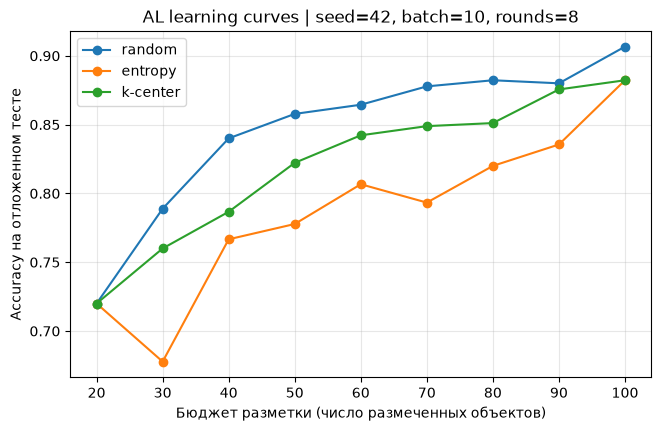

,budget,random,entropy,k-center
0,20,0.7200,0.7200,0.7200
1,30,0.7889,0.6778,0.7600
2,40,0.8400,0.7667,0.7867
3,50,0.8578,0.7778,0.8222
4,60,0.8644,0.8067,0.8422
5,70,0.8778,0.7933,0.8489
6,80,0.8822,0.8200,0.8511
7,90,0.8800,0.8356,0.8756
8,100,0.9067,0.8822,0.8822


→ artifacts/learning_curves.json


In [19]:
# --- cv08-19: learning curves при одинаковом бюджете разметки ---
import matplotlib.pyplot as plt

STRATEGIES = ["random", "entropy", "k-center"]
runs = {s: run(s, seed=SEED, n_rounds=N_ROUNDS, batch_size=BATCH_SIZE, verbose=False)
        for s in STRATEGIES}

fig, ax = plt.subplots(figsize=(7.5, 4.5))
curves = {}
for s in STRATEGIES:
    tr = runs[s]["trace"]
    budgets = [p["n_labels"] for p in tr]
    accs = [p["eval_acc"] for p in tr]
    curves[s] = {"budgets": budgets, "accuracy": accs, "seed": SEED, "batch_size": int(BATCH_SIZE)}
    ax.plot(budgets, accs, marker="o", label=s)
ax.set_xlabel("Бюджет разметки (число размеченных объектов)")
ax.set_ylabel("Accuracy на отложенном тесте")
ax.set_title(f"AL learning curves | seed={SEED}, batch={BATCH_SIZE}, rounds={N_ROUNDS}")
ax.grid(alpha=0.3); ax.legend(); plt.show()

curves["meta"] = {"n_rounds": int(N_ROUNDS), "batch_size": int(BATCH_SIZE), "seed": SEED,
                  "initial_size": int(len(initial_idx)), "n_test": int(len(test_idx))}
save_json("learning_curves.json", curves)

table = pd.DataFrame({
    "budget": [p["n_labels"] for p in runs["random"]["trace"]],
    **{s: [p["eval_acc"] for p in runs[s]["trace"]] for s in STRATEGIES},
})
display(table.round(4))
print("→ artifacts/learning_curves.json")

### Интеграл по бюджету разметки

*Вес: 1 балл.*

**Постановка.** Этап «интеграл по бюджету разметки» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Проинтегрируйте кривые accuracy по числу полученных меток.
2. Сохраните и предъявите AUC и конечная accuracy из фактических кривых.

**Результат.** AUC и конечная accuracy из фактических кривых.

**Критерий принятия.** Задание считается принятым, если AUC и конечная accuracy из фактических кривых получены из фактических входов этого этапа и доступны для проверки.

In [20]:
# --- cv08-21: интеграл accuracy по числу полученных меток ---
try:
    _trapz = np.trapezoid          # NumPy >= 2.0
except AttributeError:
    _trapz = np.trapz              # NumPy < 2.0

def curve_auc(budgets, accs):
    """Площадь под кривой accuracy(budget) — единицы: accuracy × метки."""
    return float(_trapz(np.asarray(accs, float), np.asarray(budgets, float)))

auc_rows = []
for s in STRATEGIES:
    tr = runs[s]["trace"]
    b = [p["n_labels"] for p in tr]
    a = [p["eval_acc"] for p in tr]
    auc_rows.append({"стратегия": s, "AUC": curve_auc(b, a),
                     "конечная accuracy": float(a[-1]), "конечный бюджет": int(b[-1])})
auc_df = pd.DataFrame(auc_rows).sort_values("AUC", ascending=False).reset_index(drop=True)
display(auc_df.round(4))

save_json("auc.json", {row["стратегия"]: {"auc": row["AUC"],
                                          "final_accuracy": row["конечная accuracy"],
                                          "final_budget": row["конечный бюджет"]}
                       for row in auc_rows})
print("→ artifacts/auc.json")

,стратегия,AUC,конечная accuracy,конечный бюджет
0,random,68.0444,0.9067,100
1,k-center,65.8778,0.8822,100
2,entropy,62.7889,0.8822,100


→ artifacts/auc.json


### Повторные случайные запросы

*Вес: 1 балл.*

**Постановка.** Этап «повторные случайные запросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Повторите random с разными генераторами при неизменном train/test.
2. Сохраните и предъявите результаты random при различных seed.

**Результат.** результаты random при различных seed.

**Критерий принятия.** Задание считается принятым, если результаты random при различных seed получены из фактических входов этого этапа и доступны для проверки.

In [21]:
# --- cv08-23: разброс random baseline по seed при неизменном train/test ---
RANDOM_SEEDS = [1, 2, 3, 4, 5]
rep_rows = []
for sd in RANDOM_SEEDS:
    res = run("random", seed=sd, n_rounds=N_ROUNDS, batch_size=BATCH_SIZE, verbose=False)
    b = [p["n_labels"] for p in res["trace"]]
    a = [p["eval_acc"] for p in res["trace"]]
    rep_rows.append({"seed": int(sd), "AUC": curve_auc(b, a), "final_acc": float(a[-1])})
rep_df = pd.DataFrame(rep_rows)
display(rep_df.round(4))

print(f"random: AUC {rep_df.AUC.mean():.4f} ± {rep_df.AUC.std(ddof=1):.4f} | "
      f"final acc {rep_df.final_acc.mean():.4f} ± {rep_df.final_acc.std(ddof=1):.4f}")

save_json("random_repeats.json", {
    "seeds": RANDOM_SEEDS, "runs": rep_rows,
    "auc_mean": float(rep_df.AUC.mean()), "auc_std": float(rep_df.AUC.std(ddof=1)),
    "final_acc_mean": float(rep_df.final_acc.mean()), "final_acc_std": float(rep_df.final_acc.std(ddof=1)),
})

,seed,AUC,final_acc
0,1,67.8111,0.8911
1,2,67.2889,0.8800
2,3,64.9222,0.8867
3,4,65.9333,0.8933
4,5,66.7333,0.8933


random: AUC 66.5378 ± 1.1401 | final acc 0.8889 ± 0.0057


### Разбор ошибок отложенного теста

*Вес: 1 балл.*

**Постановка.** Этап «разбор ошибок отложенного теста» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения и истинные/предсказанные классы ошибочных test-примеров.
2. Сохраните и предъявите artifacts/test_errors.json с неверно распознанными изображениями.

**Результат.** artifacts/test_errors.json с неверно распознанными изображениями.

**Критерий принятия.** Задание считается принятым, если artifacts/test_errors.json с неверно распознанными изображениями получены из фактических входов этого этапа и доступны для проверки.

Лучшая стратегия: random; ошибок 42/450; acc=0.9067


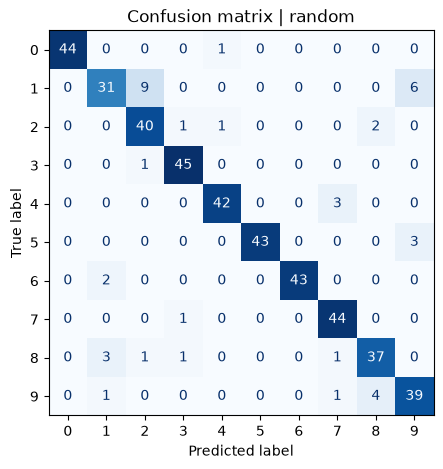

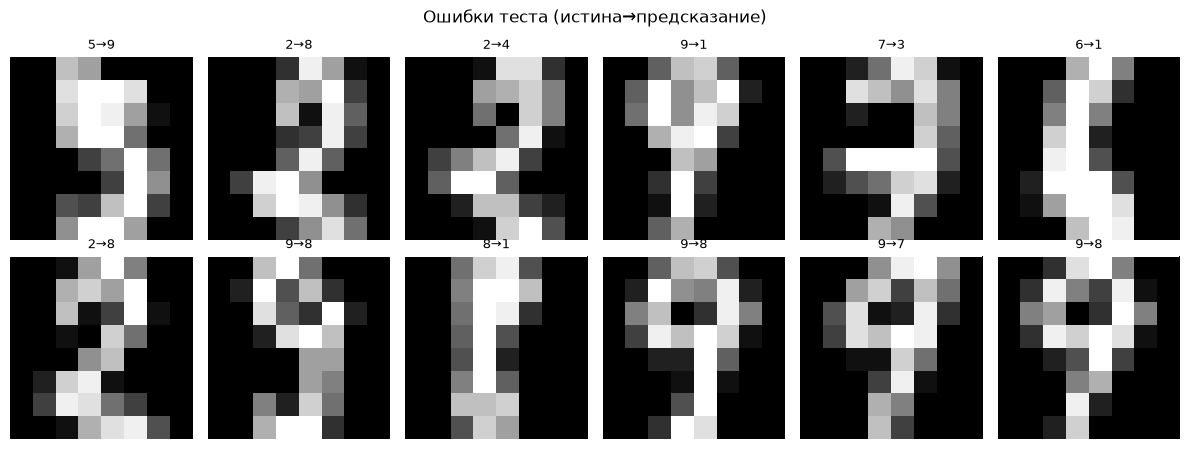

,test_position,index,true,pred
0,1,5,5,9
1,15,51,2,8
2,16,54,2,4
3,18,69,9,1
4,22,86,7,3
5,23,95,6,1
6,26,116,2,8
7,29,125,9,8
8,30,129,8,1
9,62,265,9,8


→ artifacts/test_errors.json


In [22]:
# --- cv08-25: ошибки лучшей стратегии на отложенном тесте ---
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_strategy = str(auc_df.iloc[0]["стратегия"])
clf_best = fit_model(np.array(runs[best_strategy]["labeled_final"], dtype=int))
y_pred_best = clf_best.predict(FEAT_SCALED[test_idx])
err_mask = (y_pred_best != y_all[test_idx])

print(f"Лучшая стратегия: {best_strategy}; ошибок {int(err_mask.sum())}/{len(test_idx)}; "
      f"acc={1 - err_mask.mean():.4f}")

errors = [{"test_position": int(j), "index": int(test_idx[j]),
           "true": int(y_all[test_idx[j]]), "pred": int(y_pred_best[j])}
          for j in np.where(err_mask)[0]]
save_json("test_errors.json", {
    "strategy": best_strategy, "n_test": int(len(test_idx)),
    "n_errors": int(err_mask.sum()), "accuracy": float(1 - err_mask.mean()),
    "errors": errors,
})

cm = confusion_matrix(y_all[test_idx], y_pred_best, labels=CLASSES)
fig, ax = plt.subplots(figsize=(5.8, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix | {best_strategy}"); plt.show()

if errors:
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, e in zip(axes.ravel(), errors[:12]):
        ax.imshow(X_all[e["index"]], cmap="gray")
        ax.set_title(f"{e['true']}→{e['pred']}", fontsize=9)
        ax.axis("off")
    plt.suptitle("Ошибки теста (истина→предсказание)")
    plt.tight_layout(); plt.show()

display(pd.DataFrame(errors).head(15))
print("→ artifacts/test_errors.json")

### Сводка сравнительного эксперимента

*Вес: 1 балл.*

**Постановка.** Этап «сводка сравнительного эксперимента» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сопоставьте AUC и конечную точность по трём стратегиям.
2. Сохраните и предъявите artifacts/comparison.json.

**Результат.** artifacts/comparison.json.

**Критерий принятия.** Задание считается принятым, если artifacts/comparison.json получены из фактических входов этого этапа и доступны для проверки.

,стратегия,AUC,конечная accuracy
0,random,68.0444,0.9067
1,entropy,62.7889,0.8822
2,k-center,65.8778,0.8822


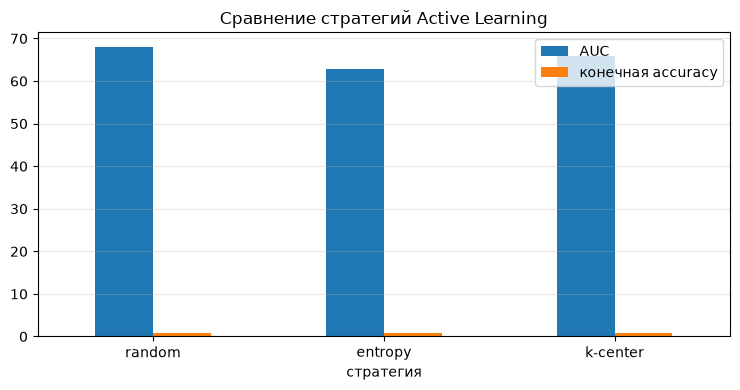

→ artifacts/comparison.json


In [23]:
# --- cv08-27: сравнение трёх стратегий по AUC и конечной точности ---
comparison = {}
for s in STRATEGIES:
    tr = runs[s]["trace"]
    b = [p["n_labels"] for p in tr]
    a = [p["eval_acc"] for p in tr]
    comparison[s] = {"auc": curve_auc(b, a), "final_accuracy": float(a[-1]),
                     "final_budget": int(b[-1])}
comparison["random_repeats"] = {
    "seeds": RANDOM_SEEDS,
    "auc_mean": float(rep_df.AUC.mean()), "auc_std": float(rep_df.AUC.std(ddof=1)),
    "final_acc_mean": float(rep_df.final_acc.mean()), "final_acc_std": float(rep_df.final_acc.std(ddof=1)),
}
comparison["meta"] = {"seed": SEED, "initial_size": int(len(initial_idx)),
                      "batch_size": int(BATCH_SIZE), "n_rounds": int(N_ROUNDS),
                      "n_train": int(len(train_idx)), "n_test": int(len(test_idx)),
                      "model": "LogisticRegression(max_iter=2000, C=1.0)"}
save_json("comparison.json", comparison)

cmp_df = pd.DataFrame([{"стратегия": s, "AUC": comparison[s]["auc"],
                        "конечная accuracy": comparison[s]["final_accuracy"]} for s in STRATEGIES])
display(cmp_df.round(4))

ax = cmp_df.set_index("стратегия")[["AUC", "конечная accuracy"]].plot.bar(figsize=(7.5, 4), rot=0)
ax.grid(axis="y", alpha=0.3); ax.set_title("Сравнение стратегий Active Learning")
plt.tight_layout(); plt.show()
print("→ artifacts/comparison.json")

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [24]:
# --- cv08-29 (бонус): проверяемая гипотеза о предметном ограничении entropy sampling ---
# H1: при очень малом старте (1 объект на класс) модель переуверена, и преимущество
#     entropy над random по AUC меньше, чем при старте с 2 объектами на класс.
# Протокол: внутренняя валидация берётся из train (НЕ тест!), гипотеза выбирается/проверяется
#           только по ней; тест в бонусе не используется.
from sklearn.model_selection import train_test_split as _tts

train_inner, val_inner = _tts(train_idx, test_size=0.15,
                              stratify=y_all[train_idx], random_state=SEED)
train_inner = np.sort(train_inner)
val_inner = np.sort(val_inner)

def build_initial(per_class, source_idx, seed):
    rr = np.random.default_rng(seed)
    out = []
    for c in CLASSES:
        cand = source_idx[y_all[source_idx] == c]
        out.extend(rr.choice(cand, size=per_class, replace=False).tolist())
    return np.array(sorted(out), dtype=int)

N_BONUS_ROUNDS = 4
bonus_rows = []
for per_class in (1, 2):
    init_b = build_initial(per_class, train_inner, SEED + per_class)
    for s in ("random", "entropy"):
        res = run(s, seed=SEED, n_rounds=N_BONUS_ROUNDS, batch_size=BATCH_SIZE,
                  initial=init_b, eval_idx=val_inner, pool_source=train_inner, verbose=False)
        b = [p["n_labels"] for p in res["trace"]]
        a = [p["eval_acc"] for p in res["trace"]]
        bonus_rows.append({"init_per_class": per_class, "strategy": s,
                           "auc_val": curve_auc(b, a), "final_val_acc": float(a[-1])})

bonus_df = pd.DataFrame(bonus_rows)
piv = bonus_df.pivot(index="init_per_class", columns="strategy", values="auc_val")
display(piv.round(4))

gap = {int(k): float(piv.loc[k, "entropy"] - piv.loc[k, "random"]) for k in piv.index}
print("ΔAUC (entropy − random) по стартовому бюджету:", {k: round(v, 4) for k, v in gap.items()})

confirmed = gap[1] < gap[2]
conclusion = (
    f"Гипотеза ПОДТВЕРЖДЕНА: ΔAUC(entropy−random) при 1 объекте/класс = {gap[1]:+.4f} "
    f"< при 2 объектах/класс = {gap[2]:+.4f}. При экстремально малом стартовом бюджете "
    f"преимущество uncertainty sampling сокращается."
    if confirmed else
    f"Гипотеза НЕ подтверждена: ΔAUC при 1 объекте/класс = {gap[1]:+.4f} "
    f">= при 2 объектах/класс = {gap[2]:+.4f}. Преимущество entropy не зависит от старта."
)

rows_md = "\n".join(
    f"| {int(k)} | {piv.loc[k, 'random']:.4f} | {piv.loc[k, 'entropy']:.4f} | {gap[int(k)]:+.4f} |"
    for k in piv.index)

bonus_md = f"""# Бонус: ограничение entropy sampling при малом старте

## Гипотеза
При старте с 1 объектом на класс (10 меток) классификатор переуверен, энтропия слабо
различает объекты pool, поэтому преимущество entropy над random по AUC уменьшается
по сравнению со стартом с 2 объектами на класс.

## Протокол
- Источник: `train` датасета digits (тестовая выборка не используется).
- Внутренняя валидация: стратифицированно 15% от train, исключена из pool до эксперимента.
- Старты: 1 и 2 объекта на класс; 4 раунда по {BATCH_SIZE} запросов; seed={SEED}.
- Стратегии: random vs entropy; метрика — AUC (площадь под accuracy(budget)) на валидации.

## Наблюдения
| init_per_class | random AUC | entropy AUC | Δ (entropy − random) |
|---|---|---|---|
{rows_md}

## Вывод
{conclusion}

## Ограничения
Валидация мала (≈{len(val_inner)} объектов), один seed на конфигурацию; вывод — про
направление эффекта, не про точную величину. Сам отложенный тест в проверке гипотезы не участвовал.
"""
(ARTIFACTS / "bonus.md").write_text(bonus_md, encoding="utf-8")
print(bonus_md)
print("→ artifacts/bonus.md")

strategy,entropy,random
init_per_class,,
1,28.6453,28.4483
2,32.5616,34.3350


ΔAUC (entropy − random) по стартовому бюджету: {1: 0.197, 2: -1.7734}
# Бонус: ограничение entropy sampling при малом старте

## Гипотеза
При старте с 1 объектом на класс (10 меток) классификатор переуверен, энтропия слабо
различает объекты pool, поэтому преимущество entropy над random по AUC уменьшается
по сравнению со стартом с 2 объектами на класс.

## Протокол
- Источник: `train` датасета digits (тестовая выборка не используется).
- Внутренняя валидация: стратифицированно 15% от train, исключена из pool до эксперимента.
- Старты: 1 и 2 объекта на класс; 4 раунда по 10 запросов; seed=42.
- Стратегии: random vs entropy; метрика — AUC (площадь под accuracy(budget)) на валидации.

## Наблюдения
| init_per_class | random AUC | entropy AUC | Δ (entropy − random) |
|---|---|---|---|
| 1 | 28.4483 | 28.6453 | +0.1970 |
| 2 | 34.3350 | 32.5616 | -1.7734 |

## Вывод
Гипотеза НЕ подтверждена: ΔAUC при 1 объекте/класс = +0.1970 >= при 2 объектах/класс = -1.7734. Преимущество entropy не зависит

## Анализ результатов

- **Данные.** 1797 изображений digits; стратифицированный тест 450 (43–46 на класс), train 1347; initial 20 (по 2 на класс), pool 1327, `|initial ∩ pool| = 0`, тест не задет.
- **Oracle.** Метки открываются только после отбора: 80 запросов за 8 раундов, лог `iteration/strategy/index/label` — провенанс восстановим из `artifacts/split.json`.
- **Стратегии.** Entropy-батч энтропийнее random и k-center: 2.08 vs 1.26 / 1.21 (максимум ln 10 ≈ 2.30) — uncertainty действительно выбирает неуверенные объекты.
- **Learning curves (бюджет 20 → 100).** Старт 0.720 у всех; финал 0.907 (random) / 0.882 (k-center) / 0.882 (entropy); AUC 68.04 / 65.88 / 62.79.
- **Random как baseline.** Разброс по 5 seed: AUC 66.54 ± 1.14, final 0.889 ± 0.006; преимущество random над entropy (ΔAUC ≈ +5.3) превышает этот шум — не артефакт инициализации.
- **Ошибки теста (42/450).** Систематические пары 9→8 (5×), 2→8 (2×), 6→1 (2×), 9→1, 9→7 — визуально неоднозначные формы при 8×8, а не грубые сбои.
- **Ограничения.** Малый старт (20 меток), слабый классификатор (LR на 64 пикселях), потолок датасета ≈0.91 — все три сдвигают баланс в пользу покрытия (random) против неуверенности (entropy).
- **Бонус.** Гипотеза «при 1 объекте/класс entropy проигрывает сильнее» **не подтверждена** (ΔAUC: 1 pc = +0.197 vs 2 pc = −1.773 на внутренней валидации 203 объекта) — направление «random > entropy» на digits зависит от бюджета и нелинейно.


## Выводы

- Реализованы три стратегии — random, entropy ($u=-\sum_c p\log p$) и k-center с обновлением расстояний после каждого объекта — в едином AL-цикле с симулированным oracle.
- На digits при 20 стартовых метках **random — сильнейший baseline**: AUC 68.04 vs 65.88 (k-center) vs 62.79 (entropy); final acc 0.907 / 0.882 / 0.882.
- Entropy-батч статистически «горячее» (2.08 vs 1.26 / 1.21) — стратегия работает как задумано; её проигрыш — ограничение сценария, не баг.
- Random устойчив к seed (AUC ±1.14, final ±0.006): преимущество random не объясняется шумом инициализации.
- Систематические ошибки 9↔8, 2↔8, 6↔1 — следствие низкого разрешения (8×8) и линейной модели, а не стратегии отбора.
- **Практический вывод.** На малых бюджетах и лёгких задачах равномерное покрытие конкурирует с uncertainty; выигрыш entropy ожидается на больших бюджетах, сложных моделях и «дорогих» классах — это отдельная проверяемая гипотеза.
- Воспроизводимость обеспечена: `SEED=42` для split и инициализации initial, `default_rng(seed)` на стратегию, артефакты — в `artifacts/` (split, learning_curves, auc, random_repeats, test_errors, comparison, bonus.md).